In [1]:
import os

print("Current directory:", os.getcwd())
print("Files in directory:", os.listdir())


Current directory: C:\Users\snigd\Downloads\FakeNewsDetection-main\FakeNewsDetection-main
Files in directory: ['.ipynb_checkpoints', 'Fake.csv', 'FakeNewsDetection.ipynb', 'fake_news_detection_project_guide.pdf', 'README.md', 'True.csv', 'Untitled.ipynb']


In [2]:
import pandas as pd
import numpy as np
import re
import time
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

RANDOM_STATE = 42

In [3]:
fake_df = pd.read_csv("Fake.csv")
real_df = pd.read_csv("True.csv")

fake_df["label"] = 0
real_df["label"] = 1

df = pd.concat([fake_df, real_df], ignore_index=True)

print("Original dataset:", df.shape)
print(df["label"].value_counts())

Original dataset: (44898, 5)
label
0    23481
1    21417
Name: count, dtype: int64


In [4]:
df = df.dropna(subset=["title", "text"]).copy()

df["content"] = (
    df["title"].str.strip() + " " +
    df["text"].str.strip()
)

df["content"] = df["content"].apply(
    lambda text: re.sub(r"\s+", " ", text).strip()
)

df = df[df["content"] != ""].copy()

# Check for conflicting labels before removing duplicates.
conflicts = df.groupby("content")["label"].nunique()
conflicting_texts = conflicts[conflicts > 1].index

print("Conflicting articles:", len(conflicting_texts))

df = df[~df["content"].isin(conflicting_texts)]
df = df.drop_duplicates(subset=["content"])

print("Cleaned dataset:", df.shape)

Conflicting articles: 0
Cleaned dataset: (39100, 6)


In [5]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=RANDOM_STATE
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=RANDOM_STATE
)

print("Training:", len(train_df))
print("Validation:", len(valid_df))
print("Testing:", len(test_df))

Training: 27370
Validation: 5865
Testing: 5865


In [6]:
from pathlib import Path

Path("data_splits").mkdir(exist_ok=True)

train_df.to_csv("data_splits/train.csv", index=False)
valid_df.to_csv("data_splits/valid.csv", index=False)
test_df.to_csv("data_splits/test.csv", index=False)

print("Dataset splits saved.")

Dataset splits saved.


In [7]:
X_train = train_df["content"]
y_train = train_df["label"]

X_valid = valid_df["content"]
y_valid = valid_df["label"]

print("Training articles:", len(X_train))
print("Validation articles:", len(X_valid))

Training articles: 27370
Validation articles: 5865


In [8]:
tfidf_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=30000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("TF-IDF + Logistic Regression model created!")

TF-IDF + Logistic Regression model created!


In [9]:
start_time = time.time()

tfidf_model.fit(X_train, y_train)

training_time = time.time() - start_time

print("Model training completed!")
print(f"Training time: {training_time:.2f} seconds")

Model training completed!
Training time: 56.60 seconds


In [10]:
y_valid_pred = tfidf_model.predict(X_valid)

accuracy = accuracy_score(y_valid, y_valid_pred)
macro_f1 = f1_score(y_valid, y_valid_pred, average="macro")
weighted_f1 = f1_score(y_valid, y_valid_pred, average="weighted")

print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Macro F1 Score: {macro_f1:.4f}")
print(f"Weighted F1 Score: {weighted_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_valid,
    y_valid_pred,
    target_names=["Fake News", "Real News"]
))

Validation Accuracy: 0.9869
Macro F1 Score: 0.9868
Weighted F1 Score: 0.9869

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.99      2686
   Real News       0.98      0.99      0.99      3179

    accuracy                           0.99      5865
   macro avg       0.99      0.99      0.99      5865
weighted avg       0.99      0.99      0.99      5865



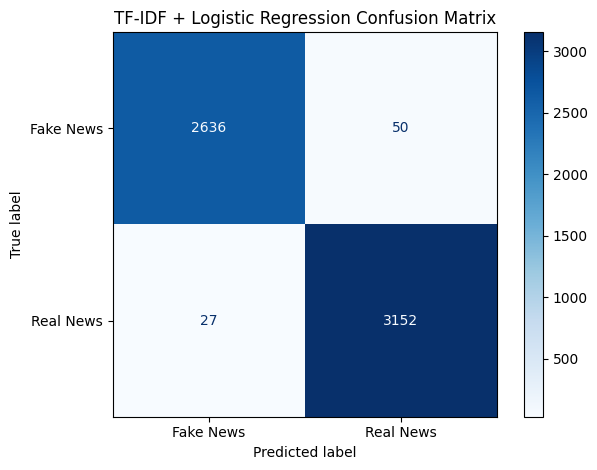

In [11]:
cm = confusion_matrix(y_valid, y_valid_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake News", "Real News"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("TF-IDF + Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)

joblib.dump(tfidf_model, "models/tfidf_logistic_regression.pkl")

print("TF-IDF model saved successfully!")

TF-IDF model saved successfully!


In [13]:
import json

baseline_results = {
    "model": "TF-IDF + Logistic Regression",
    "validation_accuracy": float(accuracy),
    "validation_macro_f1": float(macro_f1),
    "validation_weighted_f1": float(weighted_f1),
    "training_time_seconds": float(training_time)
}

with open("models/tfidf_validation_metrics.json", "w") as f:
    json.dump(baseline_results, f, indent=4)

print("Validation metrics saved!")

Validation metrics saved!


In [1]:
import pandas as pd
from pathlib import Path

Path("results").mkdir(exist_ok=True)

comparison = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression", "LSTM"],
    "Validation Accuracy": [0.9869, 0.9852],
    "Macro F1": [0.9868, 0.9851],
    "Weighted F1": [0.9869, 0.9852],
    "Training Time (seconds)": [56.60, 2887.27]
})

comparison.to_csv("results/week2_comparison.csv", index=False)

display(comparison)

,Model,Validation Accuracy,Macro F1,Weighted F1,Training Time (seconds)
0,TF-IDF + Logistic Regression,0.9869,0.9868,0.9869,56.60
1,LSTM,0.9852,0.9851,0.9852,2887.27
